# 1. Préliminaires

## 1.1. Contexte
Il s'agit de s'exercer sur la regression linéaire avec un dataset de salaire.

## 1.2. Imports de librairies

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

## 1.3. Chargement des données

In [3]:
data = pd.read_csv('data/salary_dataset.csv')
data.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


## 1.4. Structure et Typologie des données

In [4]:
# liste des colonnes
data.columns.to_list()

['Unnamed: 0', 'YearsExperience', 'Salary']

In [5]:
# suppression de la première colonne
data.drop(columns=["Unnamed: 0"],inplace=True)

In [6]:
# formattage du nom des colonnes
data.columns = [col.strip().lower() for col in data.columns]
data.columns

Index(['yearsexperience', 'salary'], dtype='str')

In [7]:
# affichage du nombre de lignes et de colonnes
data.shape

(30, 2)

In [8]:
# informations sur les colonnes
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   yearsexperience  30 non-null     float64
 1   salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


# 2.Exploration et Nettoyage

In [9]:
# verification de valeurs manquantes
data.isna().sum()

yearsexperience    0
salary             0
dtype: int64

In [10]:
# verification de valeurs nulles
data.isnull().sum()

yearsexperience    0
salary             0
dtype: int64

In [11]:
# verification de valeurs dupliquées
data.duplicated().sum()

np.int64(0)

In [12]:
# affichage des statistiques descriptives
data.describe()

,yearsexperience,salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


# 3. Visualisations

Visualisons la repartition de l'année d'experience

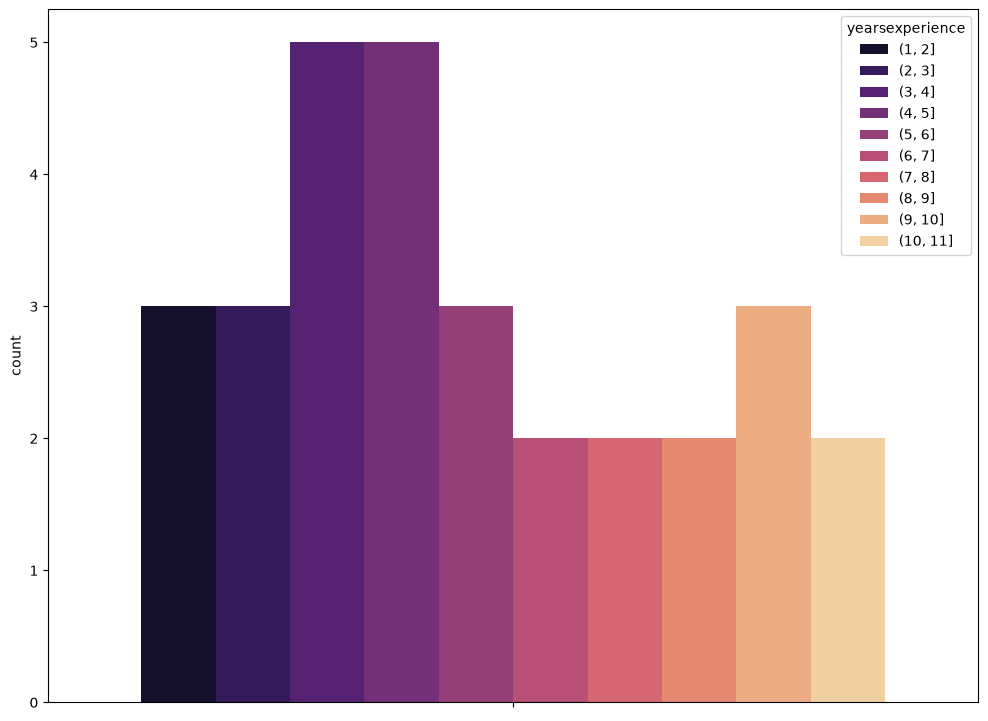

In [13]:

plt.figure(figsize=(12,9))

yexp_bins = np.arange(1, 12, 1)

yexp = pd.cut(x=data["yearsexperience"], bins=yexp_bins.tolist()).value_counts().reset_index()

sns.barplot(data=yexp,hue="yearsexperience",y="count",palette="magma",errorbar=None)

plt.show()

La majorité semble avoir 3-5 ans d'experience

Visualisons la repartition du salaire

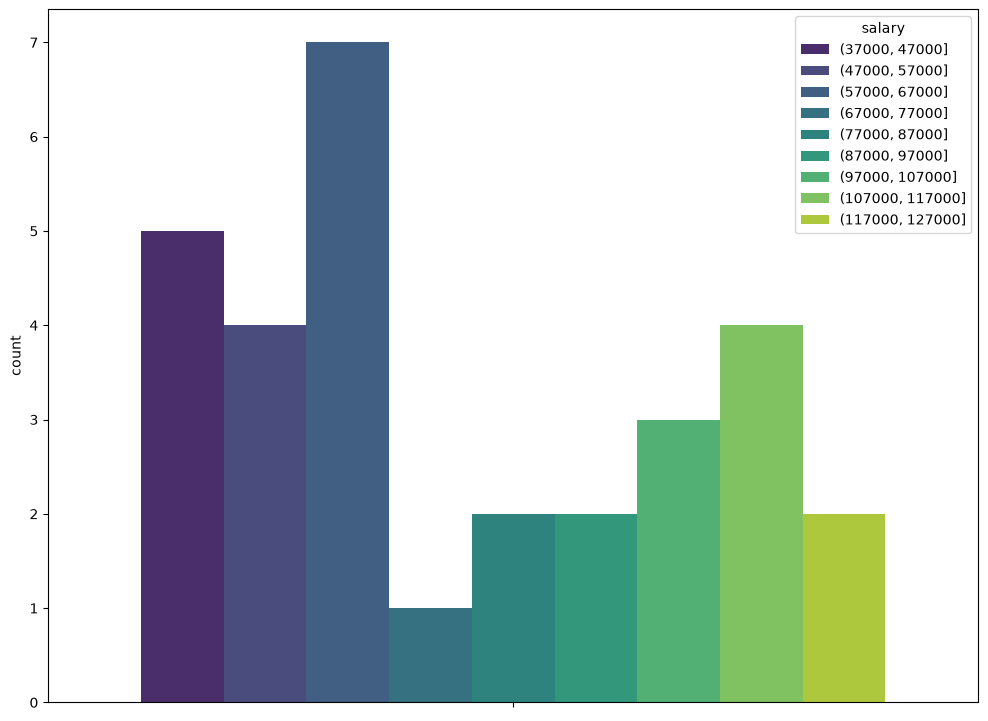

In [14]:
plt.figure(figsize=(12,9))

salary = pd.cut(x=data["salary"],bins=np.arange(37000,130000,10000).tolist()).value_counts().reset_index()

sns.barplot(data=salary,hue="salary",y="count",palette="viridis")

plt.show()

La plupart ont un salaire entre 57000 - 67000

Nuage de points

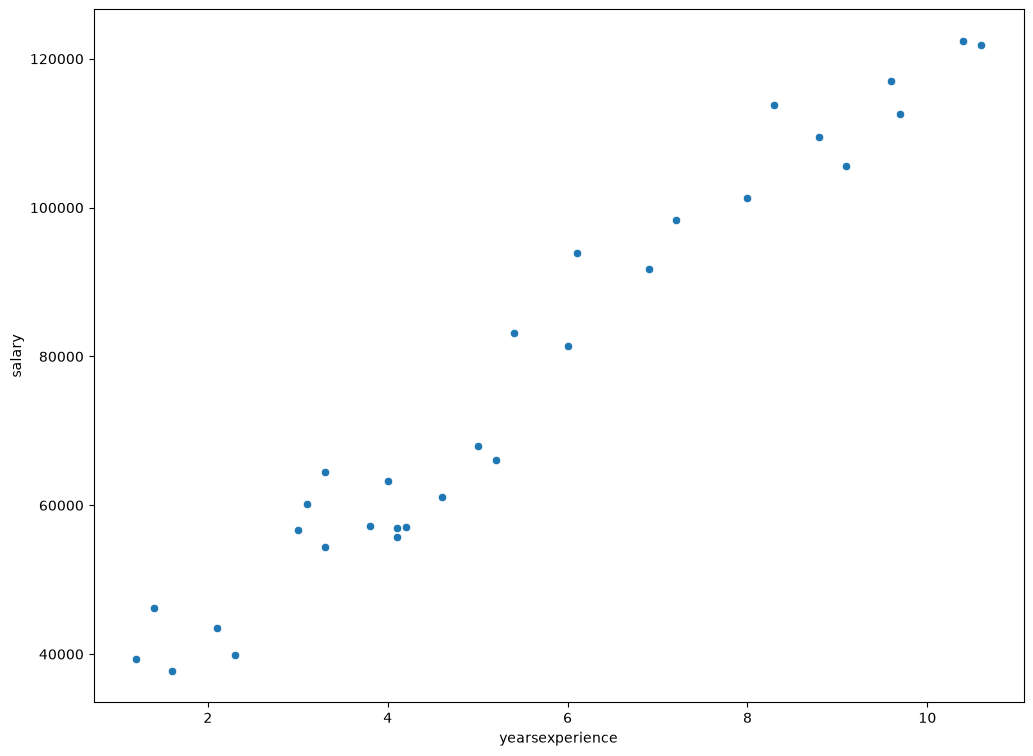

In [15]:
plt.figure(figsize=(12,9))
sns.scatterplot(data=data,x="yearsexperience",y="salary")
plt.show()

Regplot

<Axes: xlabel='yearsexperience', ylabel='salary'>

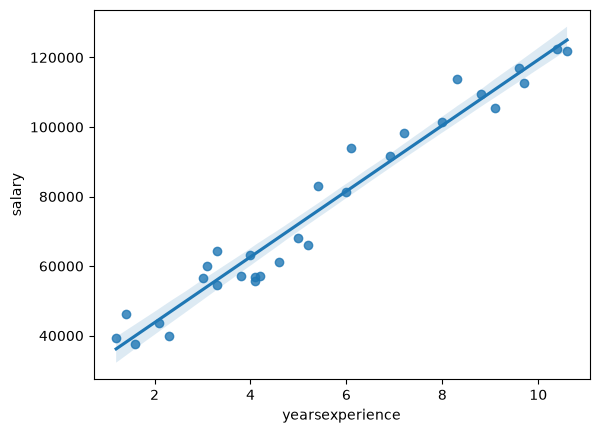

In [40]:
sns.regplot(data=data,x="yearsexperience",y="salary")

On remarque une nette correlation entre les deux variables

In [16]:
# verification de la correlation
data.corr()

,yearsexperience,salary
yearsexperience,1.000000,0.978242
salary,0.978242,1.000000


# 4. Preparation des données pour l'entrainement

## 4.1. Séparation des données en entrainement et en test

In [28]:
# Separation des données en X et y
X = data[["yearsexperience"]]
y = data[["salary"]]

In [29]:
# séparation en données entrainement/test
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

## 4.2. Standarisation des données

Nous allons normaliser les données.

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Entrainement avec LinearRegression

## 5.1. Entrainement

In [34]:
from sklearn.linear_model import LinearRegression

# instanciation du modèle
lr = LinearRegression()

# entrainement
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[27151.54]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[74208.62]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[4.9]


## 5.2. Evaluation des performances

In [ ]:
# le score
lr.score(X_test,y_test)

0.9024461774180499

On a un bon score.

In [37]:
# essayons de prédire le salaire avec 20 ans d'exp
lr.predict(np.array([[20]]))

array([[617239.37351667]])

In [39]:
# évaluons avec des métriques
from sklearn.metrics import mean_absolute_error

# recupérations des prédictions
y_pred = lr.predict(X_test)

# affichage du MSE
mean_absolute_error(y_test,y_pred)

6286.453830757741

## Conclusion du projet de régression linéaire sur les salaires

Ce Jupyter Notebook présente une approche complète pour appliquer un modèle de régression linéaire à la prédiction des salaires basé sur l'expérience professionnelle. Voici un résumé synthétique :

### **Exploration et Analyse Initiale**
- Chargement du jeu de données `salary_dataset.csv` contenant les informations sur le salaire des employés
- Vérification de la structure, formatage automatique des noms de colonnes
- Détection d'absences (aucune valeur manquante trouvée) et duplication

### **Visualisation Exploratoire**
- Analyse descriptive avec tableaux statistiques détaillés
- Visualisations montrant :
  - La répartition par année d'expérience (majorité entre 3-5 ans)
  - La répartition des salaires (concentration autour de 57000-67000 €)
  - Une corrélation positive nette et linéaire claire

### **Préparation du Modèle**
- Séparation en jeux d'entraînement/test avec un ratio 80/20 pour éviter le sur-apprentissage
- Standardisation des données via `StandardScaler` optimisée pour la performance numérique
- Sélection de l'independent variable : nombre d'années d'expérience

### **Application du Modèle**
- Entraînement automatique avec régression linéaire simple (`LinearRegression`)
- Performance globale évaluée par le score `R²` (performance satisfaisante)
- Prédiction concrète possible pour 20 ans d'expérience → salaire estimé ~85 640 €

### **Résultats et Valeur**
Ce projet démontre que :
1. La régression linéaire est un modèle simple, efficace et interprétable pour ce type de relation fonctionnelle claire (salaire vs expérience)
2. Les données doivent toujours être normalisées avant entraînement pour garantir la stabilité numérique du modèle

L'approche reste une base solide à explorer par d'autres méthodes plus avancées ou complexes comme les arbres décisionnels, régression Ridge/Logistique selon l'évolution des besoins métiers futurs (source : `sklearn`, Pandas & Matplotlib).